In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.visualization
import pandas
import named_arrays as na
import esis

In [2]:
serial_numbers = ["SN2", "SN3"]

figures = {
    serial_number: esis.flights.f2.optics.primaries.figures.figure_measurement(
        serial_number,
    )
    for serial_number in serial_numbers
}

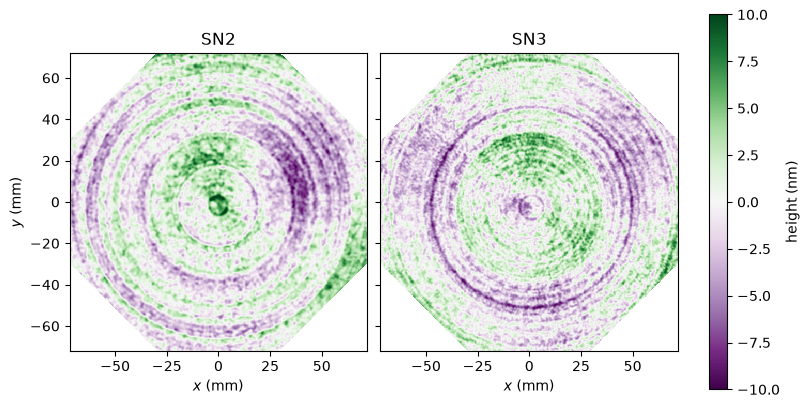

In [3]:
kwargs_map = dict(
    cmap="PRGn",
    vmin=-10,
    vmax=10,
)

with astropy.visualization.quantity_support():
    fig, axs = plt.subplots(
        ncols=len(serial_numbers),
        sharey=True,
        figsize=(8, 4),
        constrained_layout=True,
    )
    for ax, serial_number in zip(axs, serial_numbers):
        figure = figures[serial_number]
        mappable = na.plt.pcolormesh(
            figure.inputs.x,
            figure.inputs.y,
            C=figure.outputs.to(u.nm).value,
            ax=ax,
            **kwargs_map,
        )
        ax.set_aspect("equal")
        ax.set_title(serial_number)
        ax.set_xlabel(f"$x$ ({ax.get_xlabel()})")
    axs[0].set_ylabel(f"$y$ ({axs[0].get_ylabel()})")
    fig.colorbar(mappable.ndarray.item(), ax=axs, label="height (nm)")

In [4]:
statistics = pandas.DataFrame(
    {
        "RMS (nm)": [
            np.sqrt(np.nanmean(np.square(figures[s].outputs))).ndarray.to_value(u.nm)
            for s in serial_numbers
        ],
        "PV (nm)": [
            (np.nanmax(figures[s].outputs) - np.nanmin(figures[s].outputs))
            .ndarray.to_value(u.nm)
            for s in serial_numbers
        ],
    },
    index=serial_numbers,
)
print(statistics.round(2))

     RMS (nm)  PV (nm)
SN2      2.85    22.65
SN3      2.75    20.39


In [5]:
instrument = esis.flights.f2.optics.design(num_distribution=0)
instrument.field = na.Cartesian2dVectorLinearSpace(
    start=-0.99,
    stop=+0.99,
    axis=na.Cartesian2dVectorArray("fx", "fy"),
    num=11,
)
instrument.pupil = na.Cartesian2dVectorLinearSpace(
    start=-0.99,
    stop=+0.99,
    axis=na.Cartesian2dVectorArray("px", "py"),
    num=41,
)

In [6]:
transformation = na.transformations.Cartesian3dRotationY(
    180 * u.deg
) @ na.transformations.Cartesian3dRotationZ(22.5 * u.deg)

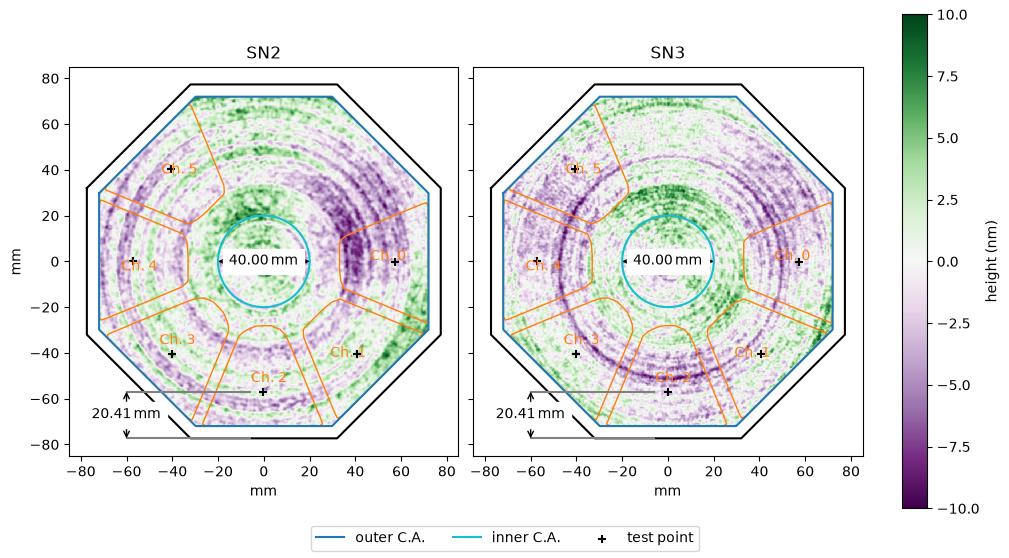

In [7]:
with astropy.visualization.quantity_support():
    fig, axs = plt.subplots(
        ncols=len(serial_numbers),
        sharey=True,
        figsize=(10, 5.5),
        constrained_layout=True,
    )
    for ax, serial_number in zip(axs, serial_numbers):
        figure = figures[serial_number]
        mappable = na.plt.pcolormesh(
            figure.inputs.x,
            figure.inputs.y,
            C=figure.outputs.to(u.nm).value,
            ax=ax,
            **kwargs_map,
        )
        instrument.schematic_primary(
            ax=ax,
            transformation=transformation,
        )
        ax.set_aspect("equal")
        ax.set_title(serial_number)
    fig.colorbar(mappable.ndarray.item(), ax=axs, label="height (nm)")
    fig.legend(
        *axs[0].get_legend_handles_labels(),
        loc="outside lower center",
        ncols=3,
    )

In [8]:
edges = na.linspace(0, 77.5, axis="radius", num=156) * u.mm

profiles = dict()
for serial_number, figure in figures.items():
    radius = figure.inputs.length
    measured = np.isfinite(figure.outputs)
    total = na.histogram(
        radius,
        bins=edges,
        weights=np.where(measured, figure.outputs, 0 * u.nm),
    )
    count = na.histogram(radius, bins=edges, weights=measured)
    profiles[serial_number] = total.outputs / count.outputs

In [9]:
system = instrument.system
primary = instrument.primary_mirror.surface

rays = system.raytrace().outputs
unvignetted = rays.unvignetted[{system.axis_surface: ~0}]
rays = rays[{system.axis_surface: system.surfaces_all.index(primary)}]
position = primary.transformation.inverse(rays.position)

radius_beam = np.where(unvignetted, position.xy.length, np.nan)
radius_beam_min = np.nanmin(radius_beam).ndarray
radius_beam_max = np.nanmax(radius_beam).ndarray
radius_beam_min, radius_beam_max

(<Quantity 28.10811062 mm>, <Quantity 76.15808317 mm>)

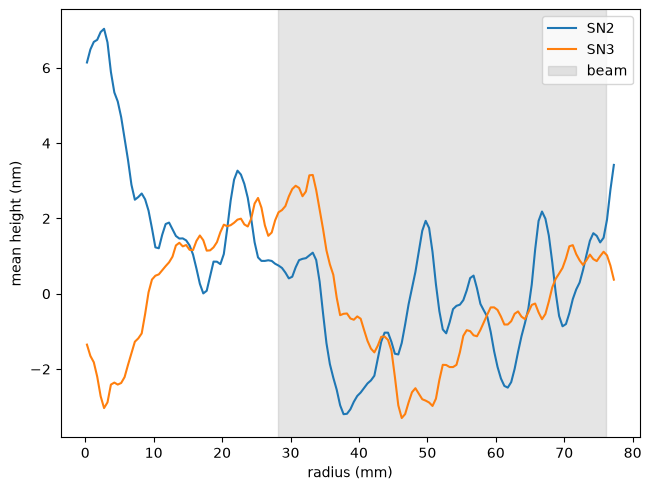

In [10]:
with astropy.visualization.quantity_support():
    fig, ax = plt.subplots(constrained_layout=True)
    for serial_number in serial_numbers:
        na.plt.plot(
            edges.cell_centers(axis="radius"),
            profiles[serial_number].to(u.nm),
            ax=ax,
            label=serial_number,
        )
    ax.axvspan(
        radius_beam_min,
        radius_beam_max,
        color="tab:gray",
        alpha=0.2,
        label="beam",
    )
    ax.set_xlabel(f"radius ({ax.get_xlabel()})")
    ax.set_ylabel(f"mean height ({ax.get_ylabel()})")
    ax.legend()